# 02 — Dove sbaglia il classificatore a feature

Partiamo dalle predizioni del notebook 01 e cerchiamo di capire **dove** e **perché** sbaglia:

1. gli errori sono sparsi sugli articoli o concentrati in alcune testate?
2. le testate sbagliate sono le stesse per tutti i modelli?
3. su quali parole si appoggia il classificatore?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from comune import carica_dataset, voto, LIVELLI, RESULTS, SEED

df = carica_dataset()
art = pd.read_csv(RESULTS + "01_tfidf_predizioni_articoli.csv")
pub = pd.read_csv(RESULTS + "01_tfidf_predizioni_testate.csv")
art["sbagliato"] = art.y_true != art.y_pred
print(len(art), "articoli,", len(pub), "testate")

19476 articoli, 439 testate


## 1. Gli errori sono un fatto di testata

Per ogni testata calcoliamo la quota di suoi articoli classificati male. Se gli errori fossero sparsi a caso,
quasi tutte le testate avrebbero una quota vicina alla media (circa 42%). Se invece dipendono dalla testata,
vedremo due gruppi: testate quasi sempre giuste e testate quasi sempre sbagliate.

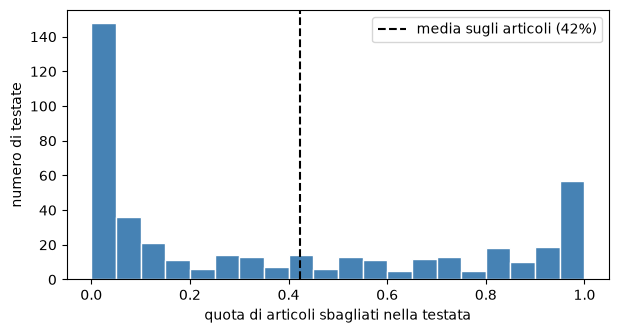

testate con meno del 20% di articoli sbagliati: 216
testate con più dell'80% di articoli sbagliati: 102
testate in mezzo: 121


In [2]:
errore_testata = art.groupby("domain").sbagliato.mean()

plt.figure(figsize=(7, 3.5))
plt.hist(errore_testata, bins=20, color="steelblue", edgecolor="white")
plt.axvline(art.sbagliato.mean(), color="black", linestyle="--", label=f"media sugli articoli ({art.sbagliato.mean():.0%})")
plt.xlabel("quota di articoli sbagliati nella testata")
plt.ylabel("numero di testate")
plt.legend()
plt.show()

print("testate con meno del 20% di articoli sbagliati:", (errore_testata < 0.2).sum())
print("testate con più dell'80% di articoli sbagliati:", (errore_testata > 0.8).sum())
print("testate in mezzo:", ((errore_testata >= 0.2) & (errore_testata <= 0.8)).sum())

Lo stesso, livello per livello: la quota di testate "quasi sempre sbagliate" non è solo un effetto del livello.

In [3]:
tab = pd.DataFrame({"livello": pub.set_index("domain").y_true, "errore": errore_testata})
tab.groupby("livello").errore.agg(
    testate="size",
    quasi_sempre_giuste=lambda e: (e < 0.2).sum(),
    quasi_sempre_sbagliate=lambda e: (e > 0.8).sum(),
).rename(index=lambda k: LIVELLI[k])

,testate,quasi_sempre_giuste,quasi_sempre_sbagliate
livello,,,
l1,152,119,16
l2,69,24,9
l3,95,54,32
l4,88,19,20
l5,35,0,25


## 2. Tutti i modelli sbagliano le stesse testate?

Confrontiamo il giudizio per testata (voto di maggioranza) del classificatore a feature con quello dei quattro modelli del paper.

In [4]:
paper = pd.read_csv("../../IrForGood/Results/derived/predictions_long.csv")
giudizi = {"TF-IDF + LR": pub.set_index("domain").pipe(lambda p: p.y_true == p.y_pred)}
for modello, g in paper.groupby("model", observed=True):
    p = g.groupby("domain").agg(y_true=("y_true", "first"), y_pred=("y_pred", voto))
    giudizi[modello] = p.y_true == p.y_pred
giudizi = pd.DataFrame(giudizi)

quanti_giusti = giudizi.sum(axis=1)
print("testate giuste per tutti e 5 i modelli:   ", (quanti_giusti == 5).sum())
print("testate sbagliate da tutti e 5 i modelli: ", (quanti_giusti == 0).sum())
print("testate su cui i modelli non sono d'accordo:", ((quanti_giusti > 0) & (quanti_giusti < 5)).sum())
print()
print("Testate sbagliate da tutti, per livello:")
print(pub.set_index("domain").loc[quanti_giusti[quanti_giusti == 0].index].y_true.map(lambda k: LIVELLI[k]).value_counts().sort_index().to_string())

testate giuste per tutti e 5 i modelli:    247
testate sbagliate da tutti e 5 i modelli:  82
testate su cui i modelli non sono d'accordo: 110

Testate sbagliate da tutti, per livello:
y_true
l1    10
l2    10
l3    25
l4    14
l5    23


## 3. Su quali parole si appoggia il classificatore

Addestriamo il classificatore su **tutto** il dataset, solo per leggerne i pesi (non per valutarlo).
Per ogni livello prendiamo le 12 parole con il peso più alto e guardiamo **quante testate** le usano
e **quanto pesa la testata che le usa di più**: una parola che viene quasi tutta da una sola testata,
o da poche testate dello stesso livello, è un'impronta della fonte, non un segnale di affidabilità.

In [5]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True,
                        max_features=100_000, strip_accents="unicode")
X = tfidf.fit_transform(df.text)
clf = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED).fit(X, df.label)
parole = np.array(tfidf.get_feature_names_out())
presente = (X > 0).tocsc()

righe = []
for livello in range(5):
    for j in np.argsort(clf.coef_[livello])[::-1][:12]:
        articoli_con_parola = df.domain.values[presente[:, j].indices]
        conteggi = pd.Series(articoli_con_parola).value_counts()
        righe.append({"livello": LIVELLI[livello], "parola": parole[j],
                      "articoli": len(articoli_con_parola), "testate": len(conteggi),
                      "quota della testata principale": round(conteggi.iloc[0] / len(articoli_con_parola), 2)})
parole_top = pd.DataFrame(righe)
pd.set_option("display.max_rows", 100)
parole_top

,livello,parola,articoli,testate,quota della testata principale
0,l1,website,2117,362,0.04
1,l1,official,2356,370,0.02
2,l1,source,1857,296,0.03
3,l1,headshot,256,48,0.05
4,l1,original source,122,42,0.16
5,l1,official website,558,153,0.03
6,l1,county,4375,342,0.01
7,l1,district,1990,343,0.02
8,l1,house headshot,232,40,0.06
9,l1,official house,231,41,0.06


Riassunto per livello: quota delle 200 parole più pesanti che vengono per più di metà da **una sola testata**.

In [6]:
righe = []
for livello in range(5):
    top = np.argsort(clf.coef_[livello])[::-1][:200]
    da_una_testata = [pd.Series(df.domain.values[presente[:, j].indices]).value_counts(normalize=True).iloc[0] > 0.5 for j in top]
    righe.append({"livello": LIVELLI[livello], "parole dominate da una sola testata": f"{np.mean(da_una_testata):.0%}"})
pd.DataFrame(righe).set_index("livello")

,parole dominate da una sola testata
livello,
l1,16%
l2,22%
l3,24%
l4,32%
l5,28%
